# Files & Paths with pathlib

Every data project reads and writes files in folders. The `pathlib` module represents a file-system path as an object. It works the same on Windows, macOS and Linux.

**After this lesson you can:**

1. Build paths with `Path` and the `/` operator.
2. Read path parts: name, suffix, parent.
3. Search for files with `glob` and `rglob`.
4. Get file metadata and analyse a real folder tree.

The real data in this lesson is **this repository**: the code analyses the course folders.

## 1. Build Paths

`Path("a") / "b" / "c.txt"` joins path parts with the correct separator for the operating system. Do not join paths with string `+`: it breaks on Windows (`\`) and with missing separators.

In [1]:
from pathlib import Path

lesson = Path.cwd()                         # the folder of this notebook
repo = lesson.parent                        # one level up: the repository root
example = repo / "M01-Python" / "09-Files & Paths with pathlib.ipynb"

print("cwd      :", lesson.name)
print("repo     :", repo.name)
print("exists   :", example.exists())
print("name     :", example.name)
print("stem     :", example.stem)
print("suffix   :", example.suffix)
print("parent   :", example.parent.name)
print("parts[-2:]:", example.parts[-2:])
print("relative :", example.relative_to(repo))
print("new name :", example.with_suffix(".py").name)

cwd      : M01-Python
repo     : FromZeroToHero-DataScience-AI-Cloud
exists   : True
name     : 09-Files & Paths with pathlib.ipynb
stem     : 09-Files & Paths with pathlib
suffix   : .ipynb
parent   : M01-Python
parts[-2:]: ('M01-Python', '09-Files & Paths with pathlib.ipynb')
relative : M01-Python/09-Files & Paths with pathlib.ipynb
new name : 09-Files & Paths with pathlib.py


## 2. Read and Write Files

`Path` has short methods for small files:

| Method | Does |
| :--- | :--- |
| `read_text(encoding=...)` / `write_text(...)` | whole text file |
| `read_bytes()` / `write_bytes(...)` | whole binary file |
| `mkdir(parents=True, exist_ok=True)` | create folders |
| `unlink(missing_ok=True)` | delete a file |
| `rename(target)` | move or rename |

Use `open()` (Lesson 08) for large files that you read line by line.

In [2]:
import tempfile

tmp = Path(tempfile.mkdtemp())
reports = tmp / "reports" / "2025" / "q1"
reports.mkdir(parents=True, exist_ok=True)
(reports / "summary.md").write_text("# Q1 summary\nRevenue grew 12%.\n", encoding="utf-8")
(reports / "data.csv").write_text("month,revenue\nJan,100\nFeb,112\n", encoding="utf-8")

for p in sorted(tmp.rglob("*")):
    kind = "dir " if p.is_dir() else "file"
    print(kind, p.relative_to(tmp))
print((reports / "summary.md").read_text(encoding="utf-8"))

dir  reports
dir  reports/2025
dir  reports/2025/q1
file reports/2025/q1/data.csv
file reports/2025/q1/summary.md
# Q1 summary
Revenue grew 12%.



## 3. Find Files with `glob` and `rglob`

- `folder.glob("*.ipynb")` finds matching names in one folder.
- `folder.rglob("*.ipynb")` searches all sub-folders (recursive).
- `*` matches any characters, `?` one character, `[0-9]` one digit.

The cell finds all lesson notebooks of the course.

In [3]:
modules = sorted(p for p in repo.glob("M[0-9][0-9]-*") if p.is_dir())
notebooks = sorted(repo.glob("M[0-9][0-9]-*/*.ipynb"))
print(f"{len(modules)} module folders, {len(notebooks)} lesson notebooks")
print("first three:", [n.relative_to(repo).as_posix() for n in notebooks[:3]])

43 module folders, 400 lesson notebooks
first three: ['M01-Python/01-Python Installation & Environment Setup.ipynb', 'M01-Python/02-Python Data Structures Overview.ipynb', 'M01-Python/03-Conditions in Python.ipynb']


## 4. File Metadata

`path.stat()` returns metadata: size in bytes (`st_size`), last modification time (`st_mtime`), and more. The next cell builds a table with one row per module: the number of notebooks and their total size.

In [4]:
from datetime import datetime

inventory = []
for m in modules:
    files = list(m.glob("*.ipynb"))
    size_mb = sum(f.stat().st_size for f in files) / 1e6
    newest = max((f.stat().st_mtime for f in files), default=None)
    inventory.append((m.name[:3], m.name[4:], len(files), size_mb,
                      datetime.fromtimestamp(newest).date() if newest else None))

print(f"{'id':<4} {'module':<45} {'files':>5} {'MB':>7}  last change")
for mid, name, n, mb, last in inventory:
    print(f"{mid:<4} {name[:44]:<45} {n:>5} {mb:>7.2f}  {last}")
total_mb = sum(r[3] for r in inventory)
print(f"\nTotal: {sum(r[2] for r in inventory)} notebooks, {total_mb:.1f} MB")

id   module                                        files      MB  last change
M01  Python                                           18    0.78  2026-11-16
M02  Software Engineering Practices                    2    0.01  2025-08-14
M03  Git & Collaboration                               2    0.01  2026-04-08
M04  Linux & Shell                                     7    0.71  2026-11-16
M05  Mathematics for Data Science (R)                  7    0.76  2026-11-16
M06  Statistics & Inference (R)                       23    4.64  2026-11-16
M07  SQL & Databases                                  14    0.62  2026-11-16
M08  NumPy, Pandas & Polars                           14    0.10  2026-02-09
M09  Data Visualization & BI                          14    1.57  2026-11-16
M10  Feature Engineering & Data Preprocessing         14    0.26  2026-11-16
M11  Data Engineering & Orchestration                  7    0.74  2026-11-16
M12  Streaming & Lakehouse                             5    0.62  2026-11-1

## 5. Visualise the Folder Tree

Notebooks store their outputs (including images) inside the file, so modules with many plots are larger. The plot shows the number of notebooks and the size per module.

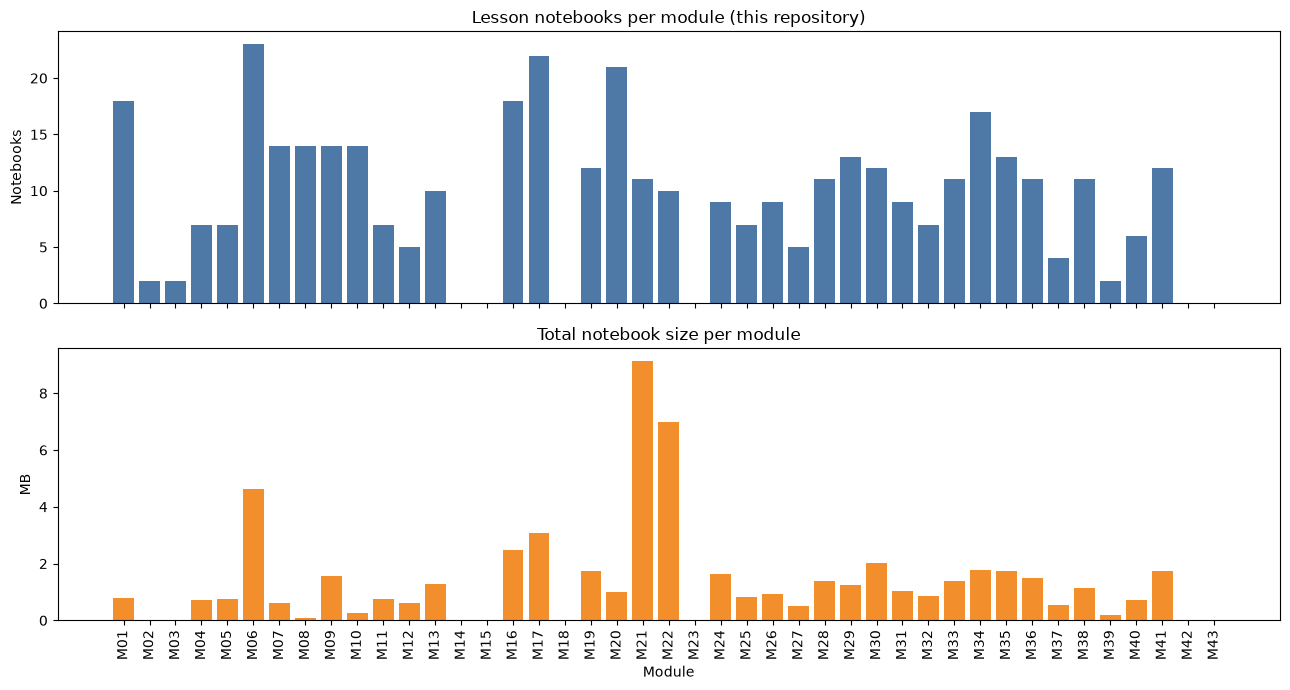

Largest module on disk: M21 Computer Vision (9.1 MB)


In [5]:
import matplotlib.pyplot as plt

ids = [r[0] for r in inventory]
counts = [r[2] for r in inventory]
sizes = [r[3] for r in inventory]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax1.bar(ids, counts, color="#4E79A7")
ax1.set(title="Lesson notebooks per module (this repository)", ylabel="Notebooks")
ax2.bar(ids, sizes, color="#F28E2B")
ax2.set(title="Total notebook size per module", ylabel="MB", xlabel="Module")
plt.setp(ax2.get_xticklabels(), rotation=90)
plt.tight_layout()
plt.show()

biggest = max(inventory, key=lambda r: r[3])
print(f"Largest module on disk: {biggest[0]} {biggest[1]} ({biggest[3]:.1f} MB)")

*Insight: Build paths from a known base folder (for example the repository root) with `Path` and `/`. Never hard-code absolute paths such as `C:\Users\me\...`: the code then runs only on your computer.*

## Real-World Use Case or Analogy

A `Path` object is like a **postal address with structure**: the country, city, street and house number are separate fields, so the post office can work with each part. A plain string is an address written in one line; it is easy to make a mistake.

Data pipelines use `pathlib` to find new input files (`raw/2025-*/*.csv`), to create output folders for each run, and to keep a project portable between a laptop, a Docker container and a cloud server.